In [13]:
import pandas as pd
from IPython.display import display, HTML

# Load the dataset
df = pd.read_csv('instagram_message_classification.csv')

# Convert the DataFrame to an HTML table
html_table = df.to_html()

# Display the HTML table
display(HTML(html_table))

,Message,Label
0,Menangkan iPhone baru! Klik di sini!,spam
1,Akun Anda telah dikompromikan. Silakan atur ulang kata sandi Anda.,fraud
2,Dapatkan pengikut gratis di Instagram secara instan!,spam
3,Selamat! Anda telah memenangkan kartu hadiah senilai $1000!,spam
4,Teman Anda menandai Anda dalam sebuah foto.,not_spam
5,"Penawaran eksklusif hanya untuk Anda, jangan lewatkan!",spam
6,Pengingat: Janji Anda besok.,not_spam
7,Seseorang menyebut Anda dalam cerita mereka.,not_spam
8,Peringatan: Upaya login tidak biasa terdeteksi. Verifikasi sekarang.,fraud
9,Paket Anda sedang dalam pengiriman.,not_spam


In [1]:
import pandas as pd

# Sample data
data = {
    'Message': [
        'Menangkan iPhone baru! Klik di sini!',
        'Akun Anda telah dikompromikan. Silakan atur ulang kata sandi Anda.',
        'Dapatkan pengikut gratis di Instagram secara instan!',
        'Selamat! Anda telah memenangkan kartu hadiah senilai $1000!',
        'Teman Anda menandai Anda dalam sebuah foto.',
        'Penawaran eksklusif hanya untuk Anda, jangan lewatkan!',
        'Pengingat: Janji Anda besok.',
        'Seseorang menyebut Anda dalam cerita mereka.',
        'Peringatan: Upaya login tidak biasa terdeteksi. Verifikasi sekarang.',
        'Paket Anda sedang dalam pengiriman.'
    ],
    'Label': ['spam', 'fraud', 'spam', 'spam', 'not_spam', 'spam', 'not_spam', 'not_spam', 'fraud', 'not_spam']
}

# Create DataFrame
df = pd.DataFrame(data)

# Save to CSV
df.to_csv('instagram_message_classification.csv', index=False)
print("Dataset saved to instagram_message_classification.csv")


Dataset saved to instagram_message_classification.csv


In [2]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load the dataset
df = pd.read_csv('instagram_message_classification.csv')

# Split the data into features and target
X = df['Message']
y = df['Label']

# Convert text data to TF-IDF features
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.3, random_state=42)

# Initialize and train the SVM model
svm_model = SVC()
svm_model.fit(X_train, y_train)

# Predict and evaluate the model
y_pred = svm_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'SVM Accuracy: {accuracy:.2f}')


SVM Accuracy: 0.00


SVM Accuracy: 0.00
Message: Klik di sini untuk mendapatkan hadiah $1000!
Prediction: spam

Message: Akun Anda berisiko, silakan verifikasi identitas Anda.
Prediction: not_spam

Message: Pengikut Instagram gratis! Segera klik tautan ini!
Prediction: spam

Message: Teman Anda mengomentari foto Anda.
Prediction: not_spam

Message: Paket Anda telah tiba, silakan ambil.
Prediction: not_spam

Message: Penawaran eksklusif hanya untuk Anda, jangan lewatkan!
Prediction: not_spam



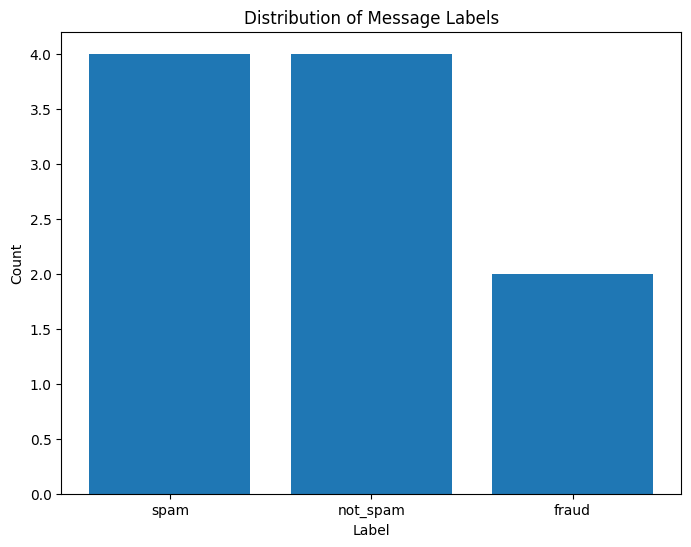

In [12]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load the dataset
df = pd.read_csv('instagram_message_classification.csv')

# Split the data into features and target
X = df['Message']
y = df['Label']

# Convert text data to TF-IDF features
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.3, random_state=42)

# Initialize and train the SVM model
svm_model = SVC()
svm_model.fit(X_train, y_train)

# Predict and evaluate the model
y_pred = svm_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'SVM Accuracy: {accuracy:.2f}')

# Test the model with new text messages
test_messages = [
    'Klik di sini untuk mendapatkan hadiah $1000!',
    'Akun Anda berisiko, silakan verifikasi identitas Anda.',
    'Pengikut Instagram gratis! Segera klik tautan ini!',
    'Teman Anda mengomentari foto Anda.',
    'Paket Anda telah tiba, silakan ambil.',
    'Penawaran eksklusif hanya untuk Anda, jangan lewatkan!'
]

# Convert new text messages to TF-IDF features
test_messages_tfidf = vectorizer.transform(test_messages)

# Predict labels for new messages
predictions = svm_model.predict(test_messages_tfidf)

# Display the predictions
for message, prediction in zip(test_messages, predictions):
    print(f'Message: {message}\nPrediction: {prediction}\n')
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame containing the messages and labels
label_counts = df['Label'].value_counts()

plt.figure(figsize=(8, 6))
plt.bar(label_counts.index, label_counts.values)
plt.title('Distribution of Message Labels')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

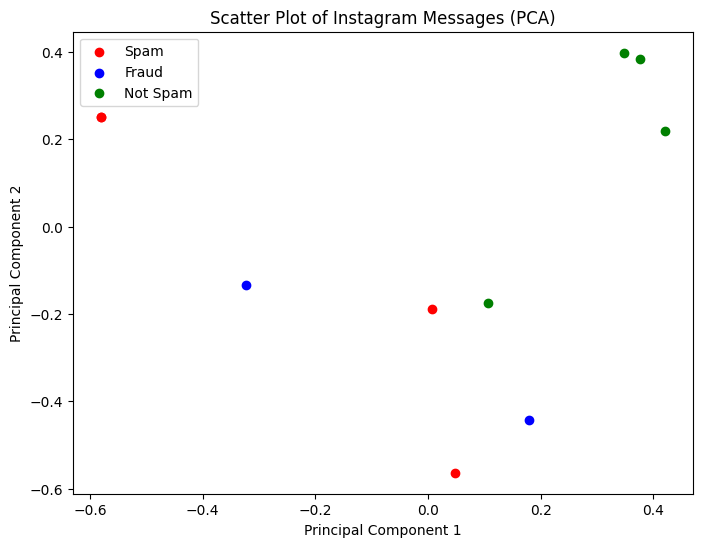

In [14]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('instagram_message_classification.csv')

# Split the data into features and target
X = df['Message']
y = df['Label']

# Convert text data to TF-IDF features
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(X)

# Reduce dimensionality using PCA
pca = PCA(n_components=2)  # Reduce to 2 dimensions for visualization
X_pca = pca.fit_transform(X_tfidf.toarray())

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[y == 'spam', 0], X_pca[y == 'spam', 1], c='red', label='Spam')
plt.scatter(X_pca[y == 'fraud', 0], X_pca[y == 'fraud', 1], c='blue', label='Fraud')
plt.scatter(X_pca[y == 'not_spam', 0], X_pca[y == 'not_spam', 1], c='green', label='Not Spam')
plt.title('Scatter Plot of Instagram Messages (PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

In [11]:

import ipywidgets as widgets
from IPython.display import display
text_input = widgets.Text(
    value='',
    placeholder='Enter your message here',
    description='Message:',
    disabled=False
)
display(text_input)
button = widgets.Button(description="Predict")
output = widgets.Output()

display(button, output)

def on_button_clicked(b):
    with output:
        message = text_input.value
        message_tfidf = vectorizer.transform([message])  # Assuming vectorizer is already defined
        prediction = svm_model.predict(message_tfidf)[0]  # Assuming svm_model is already defined
        print(f'Message: {message}\nPrediction: {prediction}\n')

button.on_click(on_button_clicked)

Text(value='', description='Message:', placeholder='Enter your message here')

Button(description='Predict', style=ButtonStyle())

Output()